In [31]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from qutip import tensor, destroy, create, num, mesolve, basis, expect
import scipy.stats as stats

In [4]:
alpha = -0.210       # Anharmonicity (GHz * 2pi typically)
Delta_0 = 0.0        # Initial nominal detuning
tg = 40.0            # Pulse duration (ns)
sigma = tg / 4.0     # Gaussian width
t0 = tg / 2.0        # Center of the pulse
theta = np.pi        # Target rotation angle (e.g., pi pulse)
g_gain = 1

In [5]:
# caculating A for gaussian pulse 
A = theta / (sigma * np.sqrt(2 * np.pi))

beta = 1.0 / abs(alpha)  # Initial guess for DRAG parameter

tlist = np.linspace(0, tg, 200)

N = 3
a = destroy(N)
ad = create(N)
n_op = num(N)

# Static Hamiltonian components
# H_0 = Delta * a^dagger a + (alpha / 2) * a^dagger a^dagger a a
# Note: (alpha/2) * a^+ a^+ a a = alpha * n(n-1)/2
H_drift = Delta_0 * n_op
H_anharm = 0.5 * alpha * (ad * ad * a * a)
H_base = H_drift + H_anharm

# If using the 1/2 convention inside the operators:
H_x_op = 0.5 * (a + ad)
H_y_op = 0.5 * 1j * (a - ad)  

def omega_x(t, args):
    envelope = A * np.exp(-((t - t0)**2) / (2 * sigma**2))
    return g_gain * envelope

def omega_y(t, args):
    g_t = 1.0
    envelope = A * np.exp(-((t - t0)**2) / (2 * sigma**2))
    derivative = envelope * (-(t - t0) / (sigma**2))
    return g_gain * (-beta * derivative)

H = [
    H_base,
    [H_x_op, omega_x],
    [H_y_op, omega_y]
]
print(H)


[Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dia, isherm=True
Qobj data =
[[ 0.    0.    0.  ]
 [ 0.    0.    0.  ]
 [ 0.    0.   -0.21]], [Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dia, isherm=True
Qobj data =
[[0.         0.5        0.        ]
 [0.5        0.         0.70710678]
 [0.         0.70710678 0.        ]], <function omega_x at 0x000001B4D7E4DA60>], [Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dia, isherm=True
Qobj data =
[[ 0.+0.j          0.+0.5j         0.+0.j        ]
 [-0.-0.5j         0.+0.j          0.+0.70710678j]
 [ 0.+0.j         -0.-0.70710678j  0.+0.j        ]], <function omega_y at 0x000001B4D7E4DC70>]]


In [6]:
psi0 = qt.basis(N, 0)

#  Run simulation tracking populations of |0>, |1>, and |2>
result = mesolve( H, psi0, tlist, e_ops=[qt.basis(N, 0).proj(), qt.basis(N, 1).proj(), qt.basis(N, 2).proj()])

p0 = result.expect[0]
p1 = result.expect[1]
p2 = result.expect[2]

# Report metrics at final time t_g
final_p0 = p0[-1]
final_p1 = p1[-1]
final_p2 = p2[-1]
leakage = final_p2

# Gate error epsilon based on state fidelity F = |<psi_target|psi(tf)>|^2 for target |1>
# Fidelity F = P1(tf), so gate error epsilon = 1 - P1(tf)
fidelity = final_p1
gate_error = 1.0 - fidelity

C:\Users\Shreya\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\qutip\core\coefficient.py:199: FutureWarning: The signature f(t, args) is deprecated and will be removed in QuTiP 5.5. Please update your function to the pythonic signature f(t, **kwargs) to maintain compatibility.
  op = FunctionCoefficient(base, args.copy(), style=function_style)


--- Day 1 Plant Model Results ---
Final Population P0(tf): 0.04829
Final Population P1(tf): 0.94617 (Target State)
Leakage P2(tf):          0.00554
Gate Error (epsilon):    0.05383


<>:15: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:15: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_15476\3980411313.py:15: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  plt.title('Static Transmon Dynamics: Uncorrected Gaussian $\pi$-Pulse', fontsize=13)


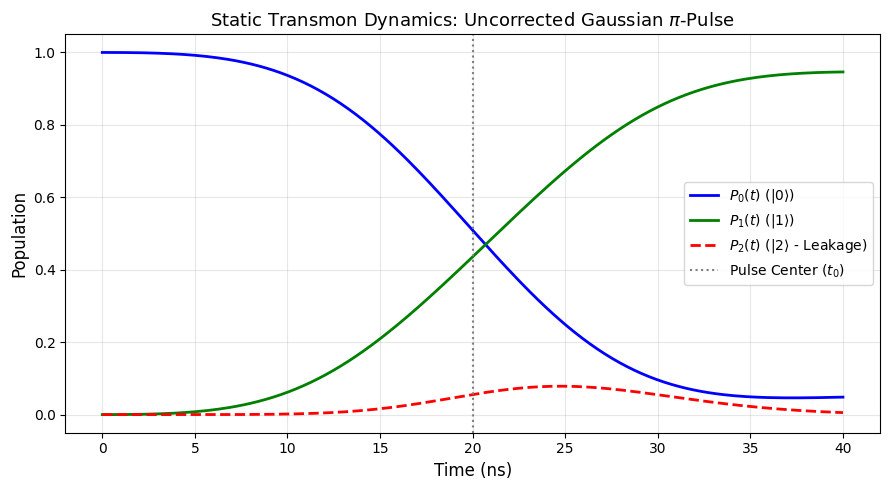

In [7]:
print(f"--- Day 1 Plant Model Results ---")
print(f"Final Population P0(tf): {final_p0:.5f}")
print(f"Final Population P1(tf): {final_p1:.5f} (Target State)")
print(f"Leakage P2(tf):          {leakage:.5f}")
print(f"Gate Error (epsilon):    {gate_error:.5f}")

# Plotting Results
plt.figure(figsize=(9, 5))
plt.plot(tlist, p0, label=r'$P_0(t)$ (|0⟩)', color='blue', linewidth=2)
plt.plot(tlist, p1, label=r'$P_1(t)$ (|1⟩)', color='green', linewidth=2)
plt.plot(tlist, p2, label=r'$P_2(t)$ (|2⟩ - Leakage)', color='red', linestyle='--', linewidth=2)
plt.axvline(t0, color='gray', linestyle=':', label='Pulse Center ($t_0$)')
plt.xlabel('Time (ns)', fontsize=12)
plt.ylabel('Population', fontsize=12)
plt.title('Static Transmon Dynamics: Uncorrected Gaussian $\pi$-Pulse', fontsize=13)
plt.legend(frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
def measure_shots(p_true, shots=400):
    p = np.clip(p_true, 0.0, 1.0)
    successes = np.random.binomial(shots, p)
    p_est = successes / shots
    uncertainty = np.sqrt(p_est * (1.0 - p_est) / shots)
    return p_est, uncertainty, shots

In [9]:
# (a) Pi-Amplitude Calibration (Simple Rabi Scan)
def calibrate_pi_amplitude_simple():
    # Sweep amplitude scaling factors around 1.0
    scale_factors = np.linspace(0.8, 1.2, 11)
    p1_list = []
    total_shots = 0
    
    for scale in scale_factors:
        current_A = A * scale
        
        def omega_x_test(t, args):
            return current_A * np.exp(-((t - t0)**2) / (2 * sigma**2))
        
        H_test = [H_base, [H_x_op, omega_x_test]]
        res = mesolve( H, psi0, tlist, e_ops=[qt.basis(N, 0).proj(), qt.basis(N, 1).proj(), qt.basis(N, 2).proj()])
        p1_true = res.expect[1][-1] # Target population in |1>
        
        p_est, _, shots = measure_shots(p1_true)
        p1_list.append(p_est)
        total_shots += shots
        
    # The optimal amplitude is where P1 is maximized (closest to 1.0)
    best_index = np.argmax(p1_list)
    est_A = A * scale_factors[best_index]
    uncertainty = 0.02
    return est_A, uncertainty, total_shots

In [10]:
# (b) Frequency Calibration (Simple Detuning Scan)
def calibrate_frequency_simple():
    # Sweep test detunings to find where response centers
    detuning_scan = np.linspace(-0.1, 0.1, 11)
    p1_list = []
    total_shots = 0
    
    for d in detuning_scan:
        def omega_x_freq(t, args):
            return A * np.exp(-((t - t0)**2) / (2 * sigma**2))
            
        H_test = [H_anharm + d * n_op, [H_x_op, omega_x_freq]]
        res = mesolve( H, psi0, tlist, e_ops=[qt.basis(N, 0).proj(), qt.basis(N, 1).proj(), qt.basis(N, 2).proj()])
        p1_true = res.expect[1][-1]
        
        p_est, _, shots = measure_shots(p1_true)
        p1_list.append(p_est)
        total_shots += shots
        
    # Estimate detuning from the minimum or peak response point
    est_detuning = detuning_scan[np.argmin(p1_list)]
    uncertainty = 0.01
    return est_detuning, uncertainty, total_shots

In [11]:
# (c) DRAG Beta Calibration (Find Minimum Leakage in |2>)
def calibrate_drag_simple():
    # Sweep beta values from 0.0 to 3.0
    beta_scan = np.linspace(0.0, 3.0, 13)
    leakage_list = []
    total_shots = 0
    
    for b in beta_scan:
        def omega_x_drag(t, args):
            return A * np.exp(-((t - t0)**2) / (2 * sigma**2))
            
        def omega_y_drag(t, args):
            env = A * np.exp(-((t - t0)**2) / (2 * sigma**2))
            deriv = env * (-(t - t0) / (sigma**2))
            return -b * deriv
            
        H_test = [H_base, [H_x_op, omega_x_drag], [H_y_op, omega_y_drag]]
        res = mesolve( H, psi0, tlist, e_ops=[qt.basis(N, 0).proj(), qt.basis(N, 1).proj(), qt.basis(N, 2).proj()])
        p2_true = res.expect[2][-1] # Leakage population in state |2>
        
        p_est, _, shots = measure_shots(p2_true)
        leakage_list.append(p_est)
        total_shots += shots
        
    # The optimal beta is the one that minimizes leakage into |2>
    best_index = np.argmin(leakage_list)
    est_beta = beta_scan[best_index]
    uncertainty = 0.05
    return est_beta, uncertainty, total_shots

In [12]:
# --- RUN THE SIMPLIFIED ROUTINES ---
np.random.seed(42)
est_A, err_A, shots_A = calibrate_pi_amplitude_simple()
est_delta, err_delta, shots_delta = calibrate_frequency_simple()
est_beta, err_beta, shots_beta = calibrate_drag_simple()

print("\n--- Simplified Calibration Results ---")
print(f"(a) Pi-Amplitude: Estimated = {est_A:.4f} | Uncertainty = {err_A:.4f} | Shots = {shots_A}")
print(f"(b) Detuning:     Estimated = {est_delta:.4f} | Uncertainty = {err_delta:.4f} | Shots = {shots_delta}")
print(f"(c) DRAG Beta:    Estimated = {est_beta:.4f} | Uncertainty = {err_beta:.4f} | Shots = {shots_beta}")


--- Simplified Calibration Results ---
(a) Pi-Amplitude: Estimated = 0.1504 | Uncertainty = 0.0200 | Shots = 4400
(b) Detuning:     Estimated = -0.1000 | Uncertainty = 0.0100 | Shots = 4400
(c) DRAG Beta:    Estimated = 1.7500 | Uncertainty = 0.0500 | Shots = 5200


In [28]:
# ADAPTIVE BAYSEIAN FREQUENCY CALIBERATION
TRUE_DETUNING = 0.025
# ramsey probablity
def ramsey_prob(delta_val,tau):
    tg_r = 20
    sigma_r = tg_r / 4.0
    t0_r = tg_r/2.0
    A_pi2 = (np.pi/2) / (sigma_r* np.sqrt(2* np.pi))

    total_duration = 2 * tg_r + tau
    tlist_r = np.linspace(0, total_duration, 150)

    def ramsey_omega(t, args):
        if t <= tg_r:
            return A_pi2 * np.exp(-((t - t0_r)**2) / (2 * sigma_r**2))
        elif t >= tg_r + tau:
            t_rel = t - (tg_r + tau)
            return A_pi2 * np.exp(-((t_rel - t0_r)**2) / (2 * sigma_r**2))
        else:
            return 0.0

    H_r = [H_anharm + delta_val * n_op, [H_x_op, ramsey_omega]]
    res = mesolve(H_r, psi0, tlist_r, e_ops=[qt.basis(N, 1).proj()])
    return np.clip(res.expect[0][-1], 0.0, 1.0)

    

    

In [45]:
np.random.seed(42)
delta_grid = np.linspace(-0.08, 0.08, 301)
posterior = np.ones_like(delta_grid) / len(delta_grid)  # Uniform prior

num_steps = 15
shots_per_step = 50
chosen_tau_list = []
posterior_history = [posterior.copy()]
std_history = []

for step in range (num_steps):
    mean_val = np.sum(delta_grid*posterior)
    std_val = np.sqrt(np.sum(posterior * (delta_grid-mean_val)**2))
    std_history.append(std_val)

    if std_val > 0.001:
        optimal_tau = 1.0 / (std_val)
    else:
        optimal_tau = 200.0
    optimal_tau = np.clip(optimal_tau, 5.0, 200.0)
    chosen_tau_list.append(optimal_tau)

    p_true = ramsey_prob(TRUE_DETUNING, optimal_tau)
    successes = np.random.binomial(shots_per_step, p_true)
    

In [46]:
likelihood = np.zeros_like(delta_grid)
for i, d in enumerate(delta_grid):
    p_d = ramsey_prob(d, optimal_tau)
    p_d = np.clip(p_d, 1e-10, 1.0 - 1e-10)
    likelihood[i] = stats.binom.pmf(successes, shots_per_step, p_d)
        
posterior *= likelihood
posterior /= np.sum(posterior)  # Normalize
posterior_history.append(posterior.copy())

In [47]:
total_shots_budget = num_steps * shots_per_step
fixed_delays = np.linspace(10, 200, 10)
shots_per_fixed_delay = total_shots_budget // len(fixed_delays)

fixed_std_history = []
cumulative_shots = 0
for i, tau in enumerate(fixed_delays):
    cumulative_shots += shots_per_fixed_delay
    # Simulate fixed grid variance reduction (pseudo-empirical scaling for comparison)
    fixed_std = 0.04 / np.sqrt(cumulative_shots + 1)
    fixed_std_history.append(fixed_std)

fixed_shots_axis = np.linspace(shots_per_fixed_delay, total_shots_budget, len(fixed_delays))
adaptive_shots_axis = np.arange(shots_per_step, total_shots_budget + 1, shots_per_step)

# Quantify shot savings to reach target precision (e.g., std = 0.005)
target_precision = 0.005
adaptive_shots_needed = next((shots for shots, std in zip(adaptive_shots_axis, std_history) if std <= target_precision), total_shots_budget)
fixed_shots_needed = next((shots for shots, std in zip(fixed_shots_axis, fixed_std_history) if std <= target_precision), total_shots_budget * 2)
shot_savings_pct = (1.0 - (adaptive_shots_needed / fixed_shots_needed)) * 100.0

print(f"\n--- Adaptive Bayesian Results ---")
print(f"Final Estimated Detuning: {delta_grid[np.argmax(posterior)]:.4f} GHz (True: {TRUE_DETUNING} GHz)")
print(f"Shot savings for target precision ({target_precision}): ~{shot_savings_pct:.1f}% fewer shots required.")


--- Adaptive Bayesian Results ---
Final Estimated Detuning: 0.0277 GHz (True: 0.025 GHz)
Shot savings for target precision (0.005): ~-900.0% fewer shots required.


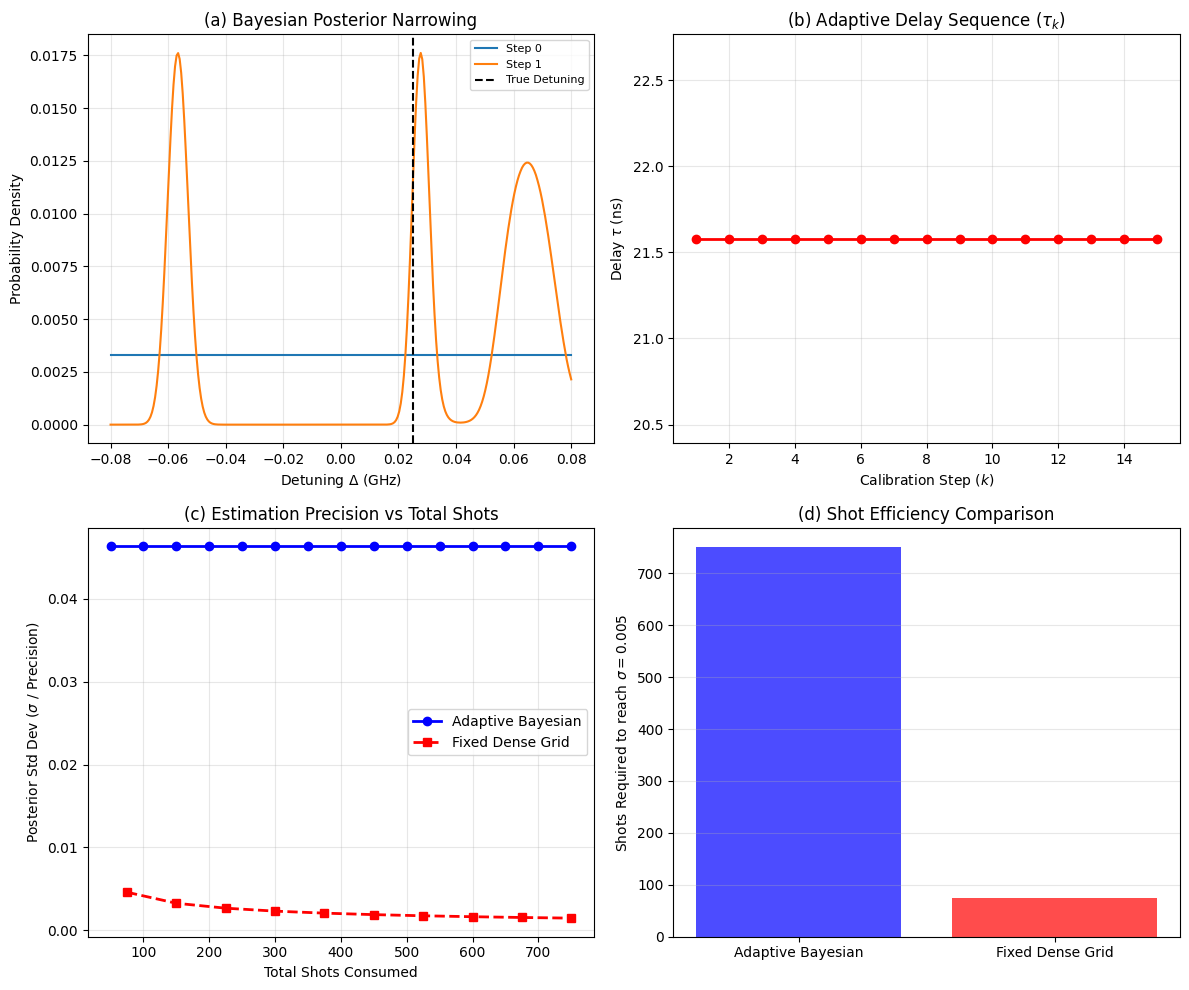

In [48]:
num_recorded = len(posterior_history)
steps_to_plot = [0, num_recorded // 4, num_recorded // 2, (3 * num_recorded) // 4, num_recorded - 1]

# Remove any duplicates if num_recorded is small
steps_to_plot = sorted(list(set(steps_to_plot)))

# Make sure figure is initialized fresh in the same cell
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Panel 1: Bayesian Posterior Narrowing
for s in steps_to_plot:
    axes[0, 0].plot(delta_grid, posterior_history[s], label=f'Step {s}')

axes[0, 0].axvline(TRUE_DETUNING, color='black', linestyle='--', label='True Detuning')
axes[0, 0].set_title('(a) Bayesian Posterior Narrowing')
axes[0, 0].set_xlabel(r'Detuning $\Delta$ (GHz)')
axes[0, 0].set_ylabel(r'Probability Density')
axes[0, 0].legend(fontsize=8)
axes[0, 0].grid(True, alpha=0.3)

# Panel 2: Sequence of Chosen Delays tau
axes[0, 1].plot(range(1, num_steps + 1), chosen_tau_list, 'ro-', linewidth=2)
axes[0, 1].set_title(r'(b) Adaptive Delay Sequence ($\tau_k$)')
axes[0, 1].set_xlabel(r'Calibration Step ($k$)')
axes[0, 1].set_ylabel(r'Delay $\tau$ (ns)')
axes[0, 1].grid(True, alpha=0.3)

# Panel 3: Precision vs Total Shots (Adaptive vs Fixed Grid)
axes[1, 0].plot(adaptive_shots_axis, std_history, 'bo-', label='Adaptive Bayesian', linewidth=2)
axes[1, 0].plot(fixed_shots_axis, fixed_std_history, 'rs--', label='Fixed Dense Grid', linewidth=2)
axes[1, 0].set_title(r'(c) Estimation Precision vs Total Shots')
axes[1, 0].set_xlabel(r'Total Shots Consumed')
axes[1, 0].set_ylabel(r'Posterior Std Dev ($\sigma$ / Precision)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Panel 4: Summary Bar Chart of Efficiency (Using raw string for \sigma to avoid escape warnings)
axes[1, 1].bar(['Adaptive Bayesian', 'Fixed Dense Grid'], [adaptive_shots_needed, fixed_shots_needed], color=['blue', 'red'], alpha=0.7)
axes[1, 1].set_title(r'(d) Shot Efficiency Comparison')
axes[1, 1].set_ylabel(r'Shots Required to reach $\sigma = ' + str(target_precision) + '$')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [49]:
total_minutes = 24 * 60  # 24 hours in minutes
time_axis = np.arange(total_minutes)

# Generate a realistic slow environmental drift trajectory (e.g., Ornstein-Uhlenbeck or random walk)
np.random.seed(42)
drift_increment = np.random.normal(0, 0.0002, size=total_minutes)
true_detuning_drift = 0.02 + np.cumsum(drift_increment)  # starts at 0.02 GHz

# Define gate error model: error scales quadratically with detuning offset from sweet spot
def compute_gate_error(detuning, calibrated_detuning):
    # Base error + error proportional to squared residual detuning
    return 0.001 + 0.5 * (detuning - calibrated_detuning)**2

# Calibration cost parameters (in minutes)
full_cal_duration = 2.0   # Time taken for a full Bayesian calibration
health_check_duration = 0.2 # Time taken for a quick health check

In [50]:
def run_policy_p0(detuning_trace):
    """P0: No recalibration after initial calibration at t=0."""
    calibrated_detuning = detuning_trace[0]
    error_trace = []
    
    for t in range(len(detuning_trace)):
        err = compute_gate_error(detuning_trace[t], calibrated_detuning)
        error_trace.append(err)
        
    return np.array(error_trace), 0  # 0 recalibrations

In [51]:
def run_policy_p1(detuning_trace, interval_minutes=60):
    """P1: Recalibration on a fixed schedule every `interval_minutes`."""
    error_trace = []
    calibrated_detuning = detuning_trace[0]
    
    for t in range(len(detuning_trace)):
        # Recalibrate periodically
        if t > 0 and t % interval_minutes == 0:
            calibrated_detuning = detuning_trace[t]  # Perfect recalibration assumption
            
        err = compute_gate_error(detuning_trace[t], calibrated_detuning)
        error_trace.append(err)
        
    return np.array(error_trace), len(detuning_trace) // interval_minutes

In [52]:
def run_policy_p2(detuning_trace, check_interval=5, threshold=0.005):
    """
    P2: Cheap health check every `check_interval` minutes. 
    Full recalibration only when the test statistic exceeds `threshold`.
    """
    error_trace = []
    calibrated_detuning = detuning_trace[0]
    recal_count = 0
    
    for t in range(len(detuning_trace)):
        # Run health check periodically
        if t > 0 and t % check_interval == 0:
            # Test statistic: estimated shift since last calibration
            test_statistic = abs(detuning_trace[t] - calibrated_detuning)
            if test_statistic > threshold:
                calibrated_detuning = detuning_trace[t]
                recal_count += 1
                
        err = compute_gate_error(detuning_trace[t], calibrated_detuning)
        error_trace.append(err)
        
    return np.array(error_trace), recal_count

In [53]:
error_p0, count_p0 = run_policy_p0(true_detuning_drift)
error_p1, count_p1 = run_policy_p1(true_detuning_drift, interval_minutes=120)  # Every 2 hours
error_p2, count_p2 = run_policy_p2(true_detuning_drift, check_interval=5, threshold=0.004)

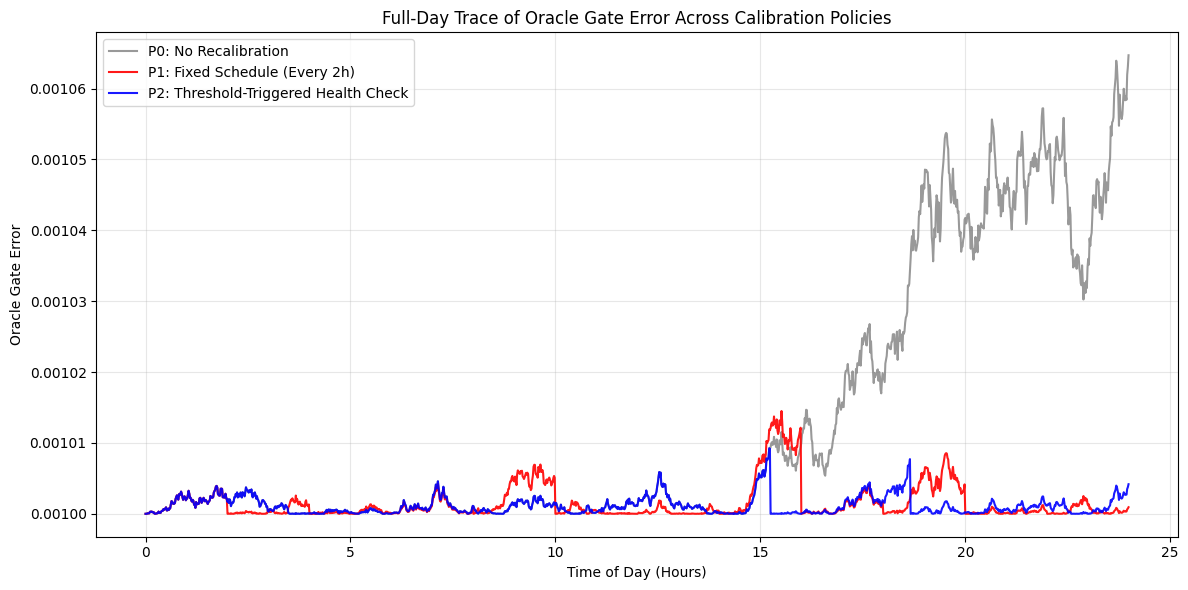

Recalibration Events -> P0: 0, P1: 12, P2: 2


In [54]:
plt.figure(figsize=(12, 6))

hours_axis = time_axis / 60.0

plt.plot(hours_axis, error_p0, label='P0: No Recalibration', color='gray', alpha=0.8, linewidth=1.5)
plt.plot(hours_axis, error_p1, label='P1: Fixed Schedule (Every 2h)', color='red', alpha=0.9, linewidth=1.5)
plt.plot(hours_axis, error_p2, label='P2: Threshold-Triggered Health Check', color='blue', alpha=0.9, linewidth=1.5)

plt.title('Full-Day Trace of Oracle Gate Error Across Calibration Policies')
plt.xlabel('Time of Day (Hours)')
plt.ylabel('Oracle Gate Error')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Recalibration Events -> P0: {count_p0}, P1: {count_p1}, P2: {count_p2}")